# Assignment 2: Quantum Fourier Transform & Phase Estimation

**Contributors**

| Name | Student ID |
|---|---|
| Vraj Shah | 2023A7PS0478G |
| Soumya Dedhia | 2023A7PS0381G |

This notebook runs Quantum Phase Estimation (QPE) on eigenstates $|v\rangle$ of 1 to 4 qubits with $m = 1, 2, 3$ counting qubits and explains every result.

All circuit code lives in the `qpe/` package of this repository, so the notebook and the unit tests (`tests/`) use exactly the same functions. The source of the graded functions is printed in Section 2.

**Notation**

| Symbol | Meaning |
|---|---|
| $n$ | number of qubits in the target state $|v\rangle$ (1 to 4) |
| $m$ | number of counting qubits (1 to 3) |
| $\varphi$ | true phase, $U|v\rangle = e^{2\pi i\varphi}|v\rangle$, $0 \le \varphi < 1$ |
| $y$ | integer read from the counting register |
| $\tilde\varphi$ | estimate of $\varphi$, $\tilde\varphi = y/2^m$ |

## 0. Setup
Run this cell first. It makes the `qpe` package importable from the `notebooks/` folder, fixes the random seed and shot count, and prints the library versions used.

In [1]:
import sys
import inspect
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

FIG_DIR = ROOT / "results" / "figures"
TAB_DIR = ROOT / "results" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator

import qpe
from qpe import core, powers
from qpe import (
    SEED, SHOTS,
    build_U, qpe_circuit, run, decode,
    basis, prepare_zero,
    controlled_power_circuit,
    exact_probabilities, theoretical_probabilities, counts_to_probabilities,
    identity_table, bits, plot_side_by_side,
)
from qpe.powers import reduce_angle

pd.set_option("display.precision", 4)
print("Python     :", sys.version.split()[0])
print("Qiskit     :", qiskit.__version__)
print("Qiskit Aer :", qiskit_aer.__version__)
print("Shots per run:", SHOTS, "| simulator seed:", SEED)

Python     : 3.11.9
Qiskit     : 2.6.2
Qiskit Aer : 0.17.2
Shots per run: 2048 | simulator seed: 1234


## 1. Background: how QPE works

If $U|v\rangle = e^{2\pi i\varphi}|v\rangle$, QPE writes the best $m$-bit approximation of $\varphi$ into the counting register:

1. Counting register in $|0\rangle^{\otimes m}$, target register in $|v\rangle$.
2. $H$ on every counting qubit.
3. Counting qubit $k$ ($k = 0,\dots,m-1$) controls $U^{2^k}$ on the target.
4. Inverse QFT on the counting register.
5. Measure $y$ and report $\tilde\varphi = y/2^m$.

**Phase kickback (step 3).** Because $|v\rangle$ is an eigenstate, the controlled gate leaves the target unchanged and the eigenvalue becomes a *relative* phase on the control:

$$C\text{-}U^{2^k}\;\tfrac{1}{\sqrt2}\big(|0\rangle+|1\rangle\big)|v\rangle=\tfrac{1}{\sqrt2}\big(|0\rangle+e^{2\pi i\,2^k\varphi}|1\rangle\big)|v\rangle .$$

After step 3 the counting register is exactly the QFT of $|2^m\varphi\rangle$:
$$\frac{1}{\sqrt{2^m}}\sum_{j=0}^{2^m-1} e^{2\pi i j\varphi}\,|j\rangle\otimes|v\rangle ,$$
so the inverse QFT undoes it. The probability of reading $y$ is

$$P(y)=\left|\frac{1}{2^m}\sum_{j=0}^{2^m-1} e^{2\pi i j(\varphi-y/2^m)}\right|^2 .$$

* If $\varphi = y/2^m$ exactly ($\varphi$ has at most $m$ binary digits), $P(y)=1$.
* Otherwise the distribution spreads, but the closest estimate still has $P \ge 4/\pi^2 \approx 0.405$.

`qpe.analysis.theoretical_probabilities(phi, m)` implements this formula and is used to predict every histogram.

## 2. Implementation

### 2.1 The phase oracle $U_n$ and the helpers
On target qubit $j$ ($j=0$ is the least-significant bit of $x$) $U_n$ applies $P(\theta_j)$ with $\theta_j = 2\pi\cdot 2^j/2^n$, so
$$U_n|x\rangle = \prod_j e^{i\theta_j x_j}|x\rangle = e^{2\pi i\,x/2^n}|x\rangle ,\qquad \varphi = x/2^n .$$

The starter helpers `build_U`, `prepare_basis_state`, `inverse_qft`, `run` and `decode` are used exactly as given. The only change is that `run` also takes an optional `seed`, so every histogram in this notebook can be reproduced.

In [2]:
for fn in (core.build_U, core.prepare_basis_state, core.inverse_qft, core.run, core.decode):
    print(inspect.getsource(fn))

def build_U(n):
    """Binary-fraction phase oracle: U|x> = exp(2*pi*i*x/2^n)|x>."""
    qc = QuantumCircuit(n, name=f"U{n}")
    for j in range(n):                       # j = 0 is the least-significant bit
        qc.p(2 * np.pi * 2**j / 2**n, j)
    return qc

def prepare_basis_state(qc, target, x):
    """Apply X to target qubit j whenever bit j of x is 1."""
    for j, q in enumerate(target):
        if (x >> j) & 1:
            qc.x(q)

def inverse_qft(qc, qubits):
    """Inverse QFT (starter code). Assumes counting qubit k controlled U^(2^k)."""
    m = len(qubits)
    for i in range(m // 2):
        qc.swap(qubits[i], qubits[m - 1 - i])
    for j in range(m):
        for k in range(j):
            qc.cp(-np.pi / 2**(j - k), qubits[k], qubits[j])
        qc.h(qubits[j])

def run(qc, shots=2048, seed=None):
    """Sample the circuit on AerSimulator and return the counts dictionary."""
    sim = AerSimulator()
    if seed is None:
        job = sim.run(transpile(qc, sim), shots=sh

### 2.2 The completed `qpe_circuit`
The four TODOs are filled in as follows:

* **TODO 1:** $H$ on every counting qubit.
* **TODO 2:** counting qubit $k$ controls $U^{2^k}$. The `method` argument chooses how $U^{2^k}$ is built (Section 2.3).
* **TODO 3:** `inverse_qft` on the counting register.
* **TODO 4:** counting qubit $k$ is measured into classical bit $k$. Qiskit prints classical bit 0 on the right, so `int(bitstring, 2)` is $y$ directly.

Setting `measure=False` returns the same circuit without measurements, which is used for exact `Statevector` probabilities. Barriers only separate the stages in the drawings and have no effect on the simulation.

In [3]:
print(inspect.getsource(core.qpe_circuit))

def qpe_circuit(U, n, m, prepare, method="repeat", measure=True):
    """Build the QPE circuit.

    Parameters
    ----------
    U : QuantumCircuit
        n-qubit unitary whose eigenphase we estimate.
    n : int
        Number of target qubits.
    m : int
        Number of counting qubits.
    prepare : callable(qc, target)
        Prepares |v> on the target qubits.
    method : {"repeat", "angle"}
        "repeat": counting qubit k applies controlled-U 2^k times (works for any U).
        "angle":  counting qubit k applies one controlled U^(2^k) built by
                  multiplying every phase angle by 2^k (U made of P / MCP gates only).
    measure : bool
        If True, measure counting qubit k into classical bit k.
    """
    qc = QuantumCircuit(m + n, m)
    count = list(range(m))           # counting qubits 0 .. m-1
    target = list(range(m, m + n))   # target qubits m .. m+n-1
    prepare(qc, target)
    qc.barrier()

    # TODO 1: H on every counting qubit
    for q i

### 2.3 Two ways to build $U^{2^k}$ (Hint 2)

* **Repetition** (`method="repeat"`): append controlled-$U$ (built as `U.to_gate().control(1)`, Hint 1) $2^k$ times. This works for any $U$, but needs $2^m-1$ controlled-$U$ calls in total.
* **Angle multiplication** (`method="angle"`): for a $U$ made only of $P(\theta)$ / MCP$(\theta)$ gates, $U^{2^k}$ is the same circuit with every angle multiplied by $2^k$ (reduced mod $2\pi$), controlled once. Same unitary, constant depth.

In [4]:
for fn in (powers.power_by_angles, powers.controlled_U, powers.append_power_repeat,
           powers.append_power_angle, powers.append_controlled_power):
    print(inspect.getsource(fn))

def power_by_angles(U, k):
    """Return U^(2^k) as a new circuit by multiplying every phase angle by 2^k.

    Only P and MCP gates are allowed in U (true for U_n and for MCP(theta)).
    Angles are reduced modulo 2*pi, so a gate that becomes the identity is
    shown as P(0) (Hint 3).
    """
    out = QuantumCircuit(U.num_qubits, name=f"{U.name}^{2**k}")
    for instruction in U.data:
        op = instruction.operation
        qubits = [U.find_bit(q).index for q in instruction.qubits]
        if op.name not in PHASE_GATE_NAMES:
            raise ValueError(
                f"Angle multiplication only works for P/MCP gates, found '{op.name}'. "
                "Use method='repeat' for this U."
            )
        angle = reduce_angle(2**k * float(op.params[0]))
        if op.name == "p":
            out.p(angle, qubits[0])
        else:
            out.mcp(angle, qubits[:-1], qubits[-1])
    return out

def controlled_U(U, label="U"):
    """Controlled-U as a gate (control is the f

## 3. Sanity check: $|0\cdots0\rangle$

$|0\cdots0\rangle$ has $x=0$, so $\varphi = 0$ for every $U_n$. A correct circuit must return $y=0$ (all zeros) with probability 1 for every $n$ and $m$, for both power methods. The table lists the exact probability of $y=0$ and the sampled counts.

In [5]:
rows = []
for n in [1, 2, 3, 4]:
    for m in [1, 2, 3]:
        for method in ["repeat", "angle"]:
            qc_exact = qpe_circuit(build_U(n), n, m, prepare_zero, method=method, measure=False)
            p0 = exact_probabilities(qc_exact, range(m))[0]
            counts = run(qpe_circuit(build_U(n), n, m, prepare_zero, method=method),
                         shots=SHOTS, seed=SEED)
            rows.append({"n": n, "m": m, "method": method,
                         "exact P(y=0)": round(float(p0), 6),
                         "counts": dict(counts),
                         "passed": bool(np.isclose(p0, 1.0)) and counts == {"0" * m: SHOTS}})
sanity = pd.DataFrame(rows)
sanity.to_csv(TAB_DIR / "sanity_check.csv", index=False)
assert sanity["passed"].all(), "Sanity check failed: the QPE circuit is wrong"
print(f"All {len(sanity)} sanity runs return all zeros with probability 1.")
sanity

All 24 sanity runs return all zeros with probability 1.


,n,m,method,exact P(y=0),counts,passed
0,1,1,repeat,1.0,{'0': 2048},True
1,1,1,angle,1.0,{'0': 2048},True
2,1,2,repeat,1.0,{'00': 2048},True
3,1,2,angle,1.0,{'00': 2048},True
4,1,3,repeat,1.0,{'000': 2048},True
5,1,3,angle,1.0,{'000': 2048},True
6,2,1,repeat,1.0,{'0': 2048},True
7,2,1,angle,1.0,{'0': 2048},True
8,2,2,repeat,1.0,{'00': 2048},True
9,2,2,angle,1.0,{'00': 2048},True


**Result.** Every one of the 24 runs (4 values of $n$ × 3 values of $m$ × 2 power methods) returns only $y = 0\cdots0$. This is what the math predicts: with $\varphi = 0$, every kickback phase $e^{2\pi i 2^k\cdot 0}=1$ is trivial, so after step 2 the counting register is $H^{\otimes m}|0\rangle^{\otimes m}$, the QFT of $|0\rangle$. The inverse QFT maps it back to $|0\rangle^{\otimes m}$. This confirms that the $H$ layer, the controlled powers and the inverse QFT fit together.

## 4. Comparing the two power methods ($n = 3$, $m = 3$)

We use $U_3$ and $|v\rangle = |101\rangle$ ($x=5$, $\varphi = 5/8 = 0.101_2$). First we check that the controlled $U^{2^k}$ blocks of the two methods are the same unitary for every $k$, then that the full QPE histograms agree.

,k,power,same unitary
0,0,1,True
1,1,2,True
2,2,4,True


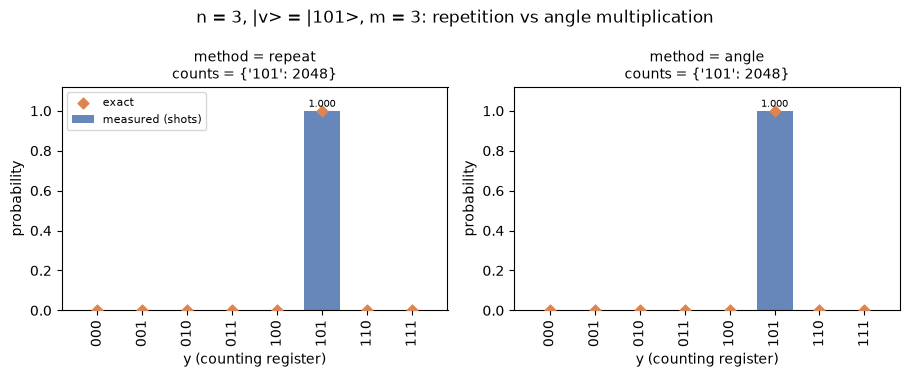

Exact probabilities identical: True
Sampled counts identical    : True


In [6]:
U3 = build_U(3)
equiv_rows = []
for k in range(3):
    rep = Operator(controlled_power_circuit(U3, k, method="repeat"))
    ang = Operator(controlled_power_circuit(U3, k, method="angle"))
    equiv_rows.append({"k": k, "power": 2**k, "same unitary": rep.equiv(ang)})
display(pd.DataFrame(equiv_rows))

panels, results = [], {}
for method in ["repeat", "angle"]:
    qc = qpe_circuit(U3, 3, 3, basis(5), method=method)
    counts = run(qc, shots=SHOTS, seed=SEED)
    exact = exact_probabilities(qpe_circuit(U3, 3, 3, basis(5), method=method, measure=False), range(3))
    results[method] = (counts, exact)
    panels.append({"measured": counts_to_probabilities(counts, 3), "exact": exact, "m": 3,
                   "title": f"method = {method}\ncounts = {dict(counts)}"})
fig = plot_side_by_side(panels, "n = 3, |v> = |101>, m = 3: repetition vs angle multiplication",
                        FIG_DIR / "power_methods_n3_m3.png")
plt.show()
assert np.allclose(results["repeat"][1], results["angle"][1])
print("Exact probabilities identical:", np.allclose(results["repeat"][1], results["angle"][1]))
print("Sampled counts identical    :", results["repeat"][0] == results["angle"][0])

In [7]:
# Cost of the two methods: controlled-U calls and transpiled size for the full n=3, m=3 circuit
basis_gates = ["u", "p", "cx"]
cost_rows = []
for method in ["repeat", "angle"]:
    qc = qpe_circuit(U3, 3, 3, basis(5), method=method, measure=False)
    tqc = transpile(qc, basis_gates=basis_gates, optimization_level=0)
    ops = tqc.count_ops()
    cost_rows.append({"method": method,
                      "controlled-U blocks": (2**3 - 1) if method == "repeat" else 3,
                      "transpiled depth": tqc.depth(),
                      "CX count": ops.get("cx", 0),
                      "total gates": sum(ops.values())})
cost = pd.DataFrame(cost_rows)
cost.to_csv(TAB_DIR / "power_method_cost_n3_m3.csv", index=False)
cost

,method,controlled-U blocks,transpiled depth,CX count,total gates
0,repeat,7,89,51,133
1,angle,3,41,27,73


**Result.** Both methods give the same unitary for each $k$, identical exact probabilities and (with the same seed) identical counts. $\varphi = 5/8$ has exactly 3 binary digits, so with $m=3$ the output is $y = 101$ with probability 1 and $\tilde\varphi = 5/8$.

They differ only in cost. Repetition uses $1+2+4 = 2^m-1 = 7$ controlled-$U$ blocks, while angle multiplication uses $m=3$, one per counting qubit. The transpiled depth and CX count in the table show the same gap. Repetition doubles in length with every extra counting qubit, while angle multiplication grows only linearly in $m$.

## 5. Which gates vanish in $U^{2^k}$ (Hint 3)

$U_n^{2^k}$ applies $P(2^k\theta_j)$ on target qubit $j$. Whenever $2^k\theta_j = 2\pi\cdot 2^{j+k}/2^n$ is a multiple of $2\pi$ (i.e. $j+k \ge n$), the gate is the identity, shown as `0 (I)` below.

In [8]:
for n in [3, 4]:
    print(f"n = {n}: angle of P(2^k * theta_j) on target qubit j")
    display(identity_table(n, 3))

n = 3: angle of P(2^k * theta_j) on target qubit j


,qubit 0,qubit 1,qubit 2
k=0 (U^1),π/4,π/2,π
k=1 (U^2),π/2,π,0 (I)
k=2 (U^4),π,0 (I),0 (I)


n = 4: angle of P(2^k * theta_j) on target qubit j


,qubit 0,qubit 1,qubit 2,qubit 3
k=0 (U^1),π/8,π/4,π/2,π
k=1 (U^2),π/4,π/2,π,0 (I)
k=2 (U^4),π/2,π,0 (I),0 (I)


**Which counting qubit learns which bit.** Write $x = x_{n-1}\cdots x_1x_0$, so $\varphi = 0.b_1b_2\cdots b_n$ with $b_i = x_{n-i}$. The phase kicked back onto counting qubit $k$ is
$$2^k\varphi \bmod 1 = 0.b_{k+1}b_{k+2}\cdots b_n ,$$
because multiplying by $2^k$ shifts the binary point $k$ places and the integer part is a full turn. This is exactly the "vanishing gates" table. For $n=3$:

* $k=0$ uses $T,S,Z$ and sees all of $0.b_1b_2b_3$.
* $k=1$ uses $S,Z,I$. The qubit-2 gate (bit $b_1$) vanishes, leaving $0.b_2b_3$.
* $k=2$ uses $Z,I,I$. Only qubit 0 (bit $b_3$) survives, leaving $0.b_3$: a phase of $0$ or $\pi$, i.e. one bit.

So the highest-power counting qubit learns the *last* binary digit of $\varphi$ on its own. Each lower qubit carries one more significant digit on top of the bits already known, and the controlled-phase corrections in the inverse QFT remove those known bits before the final $H$ reads the new one. The swaps in `inverse_qft` reverse the order, so $y = b_1b_2\cdots b_m$ reads with classical bit 0 on the right. For $n=4$, $k=2$ still leaves two gates ($S$ and $Z$, phase $0.b_3b_4$), so $m=3$ cannot isolate the 4th digit. This is why $\varphi = 11/16$ will not be exact with $m \le 3$.

## 6. Circuit diagram for $n = 2$, $m = 2$

$U_2$ on $|v\rangle = |11\rangle$ ($x=3$, $\varphi = 3/4 = 0.11_2$). The **kickback gates** are the controlled $U^{2^k}$ blocks between the first two barriers:

* counting qubit $q_0$ controls $U^1$ and picks up the phase $e^{2\pi i\varphi} = e^{2\pi i\cdot 3/4}$;
* counting qubit $q_1$ controls $U^2$ and picks up $e^{2\pi i\cdot 2\varphi} = e^{2\pi i\cdot 3/2} = e^{i\pi}$.

Three drawings follow: the angle-multiplication circuit (one labelled block per counting qubit), the repetition circuit (controlled-$U$ applied $1+2$ times), and an expanded view showing the individual $CP(2^k\theta_j)$ gates inside each kickback block.

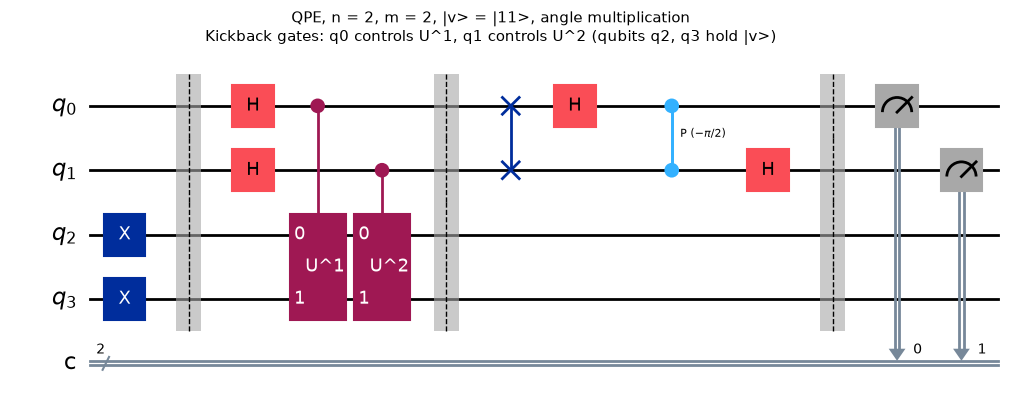

In [9]:
U2 = build_U(2)
qc22 = qpe_circuit(U2, 2, 2, basis(3), method="angle")
fig = qc22.draw("mpl", fold=-1)
fig.suptitle("QPE, n = 2, m = 2, |v> = |11>, angle multiplication\n"
             "Kickback gates: q0 controls U^1, q1 controls U^2 (qubits q2, q3 hold |v>)", fontsize=11)
fig.savefig(FIG_DIR / "circuit_n2_m2_angle.png", dpi=150, bbox_inches="tight")
fig

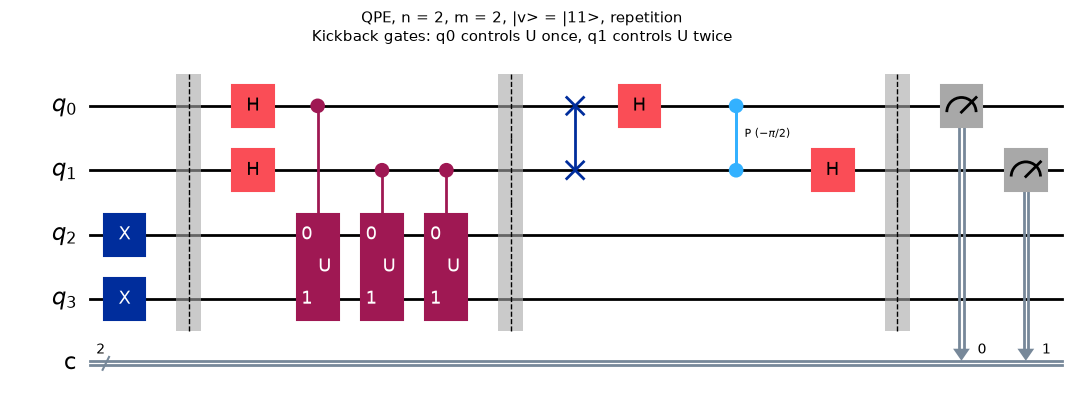

In [10]:
qc22_rep = qpe_circuit(U2, 2, 2, basis(3), method="repeat")
fig = qc22_rep.draw("mpl", fold=-1)
fig.suptitle("QPE, n = 2, m = 2, |v> = |11>, repetition\n"
             "Kickback gates: q0 controls U once, q1 controls U twice", fontsize=11)
fig.savefig(FIG_DIR / "circuit_n2_m2_repeat.png", dpi=150, bbox_inches="tight")
fig

Expanded circuit equals the qpe_circuit version: True


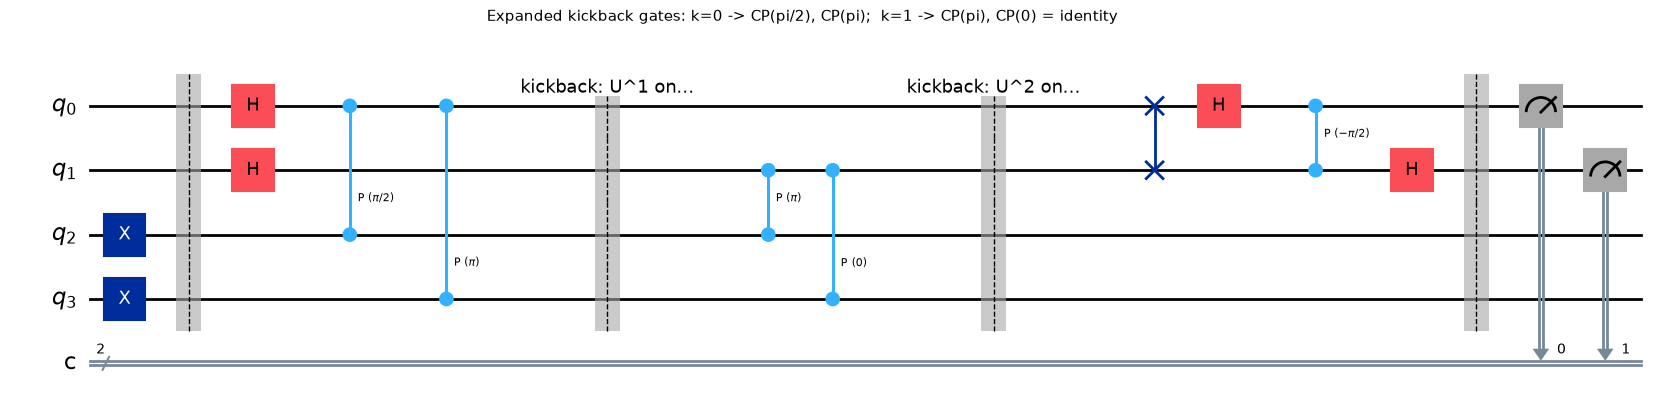

In [11]:
# Expanded view: each kickback block written out as CP(2^k * theta_j) gates
theta = [2 * np.pi * 2**j / 2**2 for j in range(2)]      # [pi/2, pi] -> S, Z
qc_exp = QuantumCircuit(4, 2)
basis(3)(qc_exp, [2, 3])
qc_exp.barrier()
for q in range(2):
    qc_exp.h(q)
for k in range(2):
    for j in range(2):
        qc_exp.cp(reduce_angle(2**k * theta[j]), k, 2 + j)
    qc_exp.barrier(label=f"kickback: U^{2**k} on q{k}")
core.inverse_qft(qc_exp, [0, 1])
qc_exp.barrier()
qc_exp.measure(0, 0)
qc_exp.measure(1, 1)

same = Operator(qc_exp.remove_final_measurements(inplace=False)).equiv(
    Operator(qc22.remove_final_measurements(inplace=False)))
print("Expanded circuit equals the qpe_circuit version:", same)
fig = qc_exp.draw("mpl", fold=-1)
fig.suptitle("Expanded kickback gates: k=0 -> CP(pi/2), CP(pi);  k=1 -> CP(pi), CP(0) = identity",
             fontsize=11)
fig.savefig(FIG_DIR / "circuit_n2_m2_expanded.png", dpi=150, bbox_inches="tight")
fig

In [12]:
counts22 = run(qc22, shots=SHOTS, seed=SEED)
print("counts:", counts22, "-> phi_tilde =", decode(max(counts22, key=counts22.get)))

counts: {'11': 2048} -> phi_tilde = 0.75


**Reading the diagram.** In the expanded view, the $k=0$ block is $CP(\pi/2)$ on target qubit 0 and $CP(\pi)$ on target qubit 1, which is controlled-$U_2 = $ controlled-$(S\otimes Z)$. In the $k=1$ block the qubit-0 gate becomes $CP(\pi)$ and the qubit-1 gate becomes $CP(2\pi) = CP(0) = I$ (Hint 3). With $|v\rangle = |11\rangle$ both target bits are 1, so $q_0$ collects $\pi/2+\pi = 3\pi/2$ ($=2\pi\cdot 3/4$) and $q_1$ collects $\pi$ ($=2\pi\cdot 3/2 \bmod 2\pi$). The inverse QFT maps this to $y = 11$, so $\tilde\varphi = 3/4$ with probability 1, since $\varphi$ has exactly $m=2$ binary digits.

## 7. Checking the analytic formula against the circuit

Before the main experiments, we confirm that the exact `Statevector` probabilities of the circuit equal the analytic $P(y)$ of Section 1 for every Part A configuration and both power methods. The formula is then a reliable predictor for the histograms that follow.

In [13]:
part_a_states = [(1, 1), (2, 3), (3, 5), (4, 11), (4, 8)]
check_rows = []
for n, x in part_a_states:
    for m in [1, 2, 3]:
        theory = theoretical_probabilities(x / 2**n, m)
        for method in ["repeat", "angle"]:
            exact = exact_probabilities(qpe_circuit(build_U(n), n, m, basis(x), method=method,
                                                    measure=False), range(m))
            check_rows.append({"n": n, "|v>": "|" + bits(x, n) + ">", "m": m, "method": method,
                               "max |statevector - formula|": float(np.max(np.abs(exact - theory)))})
formula_check = pd.DataFrame(check_rows)
assert (formula_check["max |statevector - formula|"] < 1e-9).all()
print("Largest difference over all 30 checks:", formula_check["max |statevector - formula|"].max())
formula_check

Largest difference over all 30 checks: 8.881784197001252e-16


,n,|v>,m,method,max |statevector - formula|
0,1,|1>,1,repeat,4.4409e-16
1,1,|1>,1,angle,4.4409e-16
2,1,|1>,2,repeat,6.6613e-16
3,1,|1>,2,angle,6.6613e-16
4,1,|1>,3,repeat,8.8818e-16
5,1,|1>,3,angle,8.8818e-16
6,2,|11>,1,repeat,2.2204e-16
7,2,|11>,1,angle,2.2204e-16
8,2,|11>,2,repeat,6.6613e-16
9,2,|11>,2,angle,6.6613e-16
